# Modeling

Five model families, each tuned by cross-validation on the training set and compared on the validation set. The test set is opened once, in the final section.

## 1) Setup

### 1.1) Loading the split and the preprocessors

`02_preprocessing.ipynb` saved the cleaned 70/15/15 split and the two preprocessor definitions. The definitions are unfitted: each one is refit on the training part of every cross-validation fold, inside the pipeline it belongs to.

In [1]:
import joblib
import numpy as np
import pandas as pd

RANDOM_STATE = 42
PROCESSED_DIR = "../data/processed"
MODELS_DIR = "../models"
REPORTS_DIR = "../reports"

train = joblib.load(f"{PROCESSED_DIR}/train.joblib")
val = joblib.load(f"{PROCESSED_DIR}/val.joblib")
test = joblib.load(f"{PROCESSED_DIR}/test.joblib")

X_train, y_train = train.drop(columns="TARGET"), train["TARGET"]
X_val, y_val = val.drop(columns="TARGET"), val["TARGET"]
X_test, y_test = test.drop(columns="TARGET"), test["TARGET"]

preprocessor_linear = joblib.load(f"{MODELS_DIR}/preprocessor_linear.joblib")
preprocessor_tree = joblib.load(f"{MODELS_DIR}/preprocessor_tree.joblib")

for name, X_part, y_part in [("train", X_train, y_train), ("val", X_val, y_val), ("test", X_test, y_test)]:
    print(f"{name:<6}{len(X_part):>8,} rows   {X_part.shape[1]:>3} features   "
          f"default rate {y_part.mean():.4f}")

train  215,252 rows    61 features   default rate 0.0807
val     46,126 rows    61 features   default rate 0.0807
test    46,126 rows    61 features   default rate 0.0807


### 1.2) Cross-validation

One `StratifiedKFold` object, reused by every search below, so each family is scored on identical folds and the means are directly comparable. Both metrics are computed per fold; AP decides which configuration wins.

In [2]:
from sklearn.model_selection import StratifiedKFold

N_SPLITS = 5
cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)

SCORING = {"ap": "average_precision", "roc": "roc_auc"}
REFIT = "ap"

held_out = len(next(iter(cv.split(X_train, y_train)))[1])
print(f"{N_SPLITS}-fold stratified cross-validation on the training set")
print(f"  fit on   {len(X_train) - held_out:,} rows per fold")
print(f"  score on {held_out:,} rows per fold")
print(f"\nno-skill floors   AP = {y_train.mean():.4f} (the positive rate)   ROC-AUC = 0.5")

5-fold stratified cross-validation on the training set
  fit on   172,201 rows per fold
  score on 43,051 rows per fold

no-skill floors   AP = 0.0807 (the positive rate)   ROC-AUC = 0.5


### 1.3) Pipeline shapes

Three wrappers, one per representation. Each joins a preprocessor to a model in a single estimator, which is what lets the search refit the preprocessor on every fold.

XGBoost and LightGBM read a pandas `category` dtype rather than integer codes, so a cast step sits between the two.

In [3]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer

SCALE_POS_WEIGHT = (y_train == 0).sum() / (y_train == 1).sum()


def as_categorical(X):
    """Integer codes -> pandas category dtype. For XGBoost and LightGBM only."""
    X = X.copy()
    for col in X.columns:
        if col.startswith(("categorical__", "ordinal__")):
            X[col] = X[col].astype("int8").astype("category")
    return X


def linear_pipe(model):
    """Logistic Regression: median impute, scale, one-hot."""
    return Pipeline([("prep", preprocessor_linear), ("model", model)])


def tree_pipe(model):
    """Decision Tree, Random Forest: integer codes, NaN kept."""
    return Pipeline([("prep", preprocessor_tree), ("model", model)])


def boost_pipe(model):
    """XGBoost, LightGBM: integer codes recast as pandas category."""
    return Pipeline([
        ("prep", preprocessor_tree),
        ("cast", FunctionTransformer(as_categorical)),
        ("model", model),
    ])


print(f"scale_pos_weight = {SCALE_POS_WEIGHT:.3f}")

scale_pos_weight = 11.388


### 1.4) The search helper

`scoring`, `refit`, `cv` and `return_train_score` are set in one place, so no family is evaluated on different terms from another. `n_iter=None` runs an exhaustive grid, any other value samples that many configurations.

Each call records one row: the winning configuration's cross-validated mean and standard deviation, its training score, and what the search cost.

`save_model` writes the refit winner to `models/` (each saved object is the whole pipeline).

In [4]:
import os
import time
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV

results = []


def run_search(name, pipe, space, n_iter=None, n_jobs=8):
    """Tune one family on the training set. n_iter=None -> exhaustive grid."""
    shared = dict(scoring=SCORING, refit=REFIT, cv=cv, return_train_score=True, n_jobs=n_jobs)
    if n_iter is None:
        search = GridSearchCV(pipe, space, **shared)
    else:
        search = RandomizedSearchCV(pipe, space, n_iter=n_iter,
                                    random_state=RANDOM_STATE, **shared)

    start = time.perf_counter()
    search.fit(X_train, y_train)
    wall = time.perf_counter() - start

    cv_res, best = search.cv_results_, search.best_index_
    row = {
        "model": name,
        "cv_ap": cv_res["mean_test_ap"][best],
        "cv_ap_std": cv_res["std_test_ap"][best],
        "cv_roc": cv_res["mean_test_roc"][best],
        "cv_roc_std": cv_res["std_test_roc"][best],
        "cv_gini": 2 * cv_res["mean_test_roc"][best] - 1,
        "train_ap": cv_res["mean_train_ap"][best],
        "candidates": len(cv_res["params"]),
        "wall_min": wall / 60,
        "best_params": search.best_params_,
    }
    results[:] = [r for r in results if r["model"] != name] + [row] 

    print(f"\n{'='*58}")
    print(f"{name}")
    print(f"{'='*58}")
    print(f"  CV AP        {row['cv_ap']:.4f} ± {row['cv_ap_std']:.4f}")
    print(f"  CV ROC-AUC   {row['cv_roc']:.4f} ± {row['cv_roc_std']:.4f}")
    print(f"  CV Gini      {row['cv_gini']:.4f}")
    print(f"  train AP     {row['train_ap']:.4f}   gap {row['train_ap'] - row['cv_ap']:+.4f}")
    print(f"{'='*58}")
    print(f"  Search: {row['candidates']} candidates x {N_SPLITS} folds in {row['wall_min']:.1f} min")
    params = []
    for key, value in search.best_params_.items():
        shown = f"{value:g}" if isinstance(value, (float, np.floating)) else value
        params.append(f"{key.replace('model__', '')} = {shown}")
    print(f"  Best params:  {', '.join(params)}")

    return search


def save_model(search, filename):
    """Persist the refit winner: a full pipeline, cleaned applicant in, score out."""
    path = f"{MODELS_DIR}/{filename}"
    joblib.dump(search.best_estimator_, path)
    size_kb = os.path.getsize(path) / 1e3
    size, unit = (size_kb / 1e3, "MB") if size_kb >= 1e3 else (size_kb, "KB")
    print(f"  (Saved in: {path}   {size:.1f} {unit})")

## 2) Models

### 2.1) Logistic Regression

One grid over the strength of the penalty (`C`) and its composition (`l1_ratio`) — 0 is pure L2, 1 is pure L1, 0.5 an even elastic-net mix. The `saga` solver handles all three and is stable for large dataset. `tol=1e-2`, which saga reaches in about 18 iterations.

In [5]:
from sklearn.linear_model import LogisticRegression

logreg_search = run_search(
    "Logistic Regression",
    linear_pipe(LogisticRegression(
        solver="saga",
        max_iter=300,
        tol=1e-2,
        class_weight="balanced",
        random_state=RANDOM_STATE,
    )),
    {
        "model__C": [0.01, 0.1, 1.0],
        "model__l1_ratio": [0.0, 0.5, 1.0],
    },
)

save_model(logreg_search, "logreg.joblib")


Logistic Regression
  CV AP        0.2211 ± 0.0095
  CV ROC-AUC   0.7460 ± 0.0066
  CV Gini      0.4920
  train AP     0.2226   gap +0.0015
  Search: 9 candidates x 5 folds in 1.8 min
  Best params:  C = 1, l1_ratio = 0.5
  (Saved in: ../models/logreg.joblib   24.0 KB)


#### 2.1.1) Coefficients of the winning configuration

The numeric branch is standardised, so each coefficient is the change in log-odds of default per one standard deviation of that feature, and `exp(coefficient)` is the multiplicative change in the odds.

In [6]:
best_logreg = logreg_search.best_estimator_
feature_names = best_logreg.named_steps["prep"].get_feature_names_out()
coefficients = pd.Series(best_logreg.named_steps["model"].coef_[0], index=feature_names)

print(f"{len(coefficients)} features in   "
      f"{int((coefficients == 0).sum())} zeroed by the penalty\n")

top = coefficients.reindex(coefficients.abs().sort_values(ascending=False).index).head(15)
print(pd.DataFrame({"coefficient": top, "odds_ratio": np.exp(top)}).to_string(
    formatters={"coefficient": "{:+.3f}".format, "odds_ratio": "{:.3f}".format}))

97 features in   0 zeroed by the penalty

                                                coefficient odds_ratio
numeric__EXT_SOURCE_3                                -0.493      0.611
numeric__EXT_SOURCE_2                                -0.400      0.671
categorical__CODE_GENDER_M                           +0.329      1.389
categorical__NAME_CONTRACT_TYPE_Revolving loans      -0.252      0.777
categorical__FLAG_OWN_CAR_Y                          -0.240      0.787
numeric__EXT_SOURCE_1                                -0.203      0.816
flags__IS_MISSING_AMT_REQ_CREDIT_BUREAU              +0.186      1.204
flags__IS_MISSING_EXT_SOURCE_1                       +0.181      1.199
categorical__NAME_FAMILY_STATUS_Married              -0.177      0.838
numeric__EMPLOYMENT_YEARS                            -0.147      0.863
ordinal__NAME_EDUCATION_TYPE                         -0.144      0.866
categorical__EMERGENCYSTATE_MODE_No                  -0.137      0.872
categorical__NAME_INCOME_TYPE_Pensi

### 2.2) Decision Tree

`min_samples_leaf` is a fraction of the fold, so it rescales with the data; the three values put roughly 16, 79 and 159 defaulters in a leaf, which is the range over which a leaf's default rate goes from noise to a usable estimate. `max_depth` steps 4 to 12 because capacity doubles with every level, with `None` included so the grid can reject a depth cap outright.

In [7]:
from sklearn.tree import DecisionTreeClassifier

TREE_SPACE = {
    "model__max_depth": [4, 6, 8, 12, None],
    "model__min_samples_leaf": [0.001, 0.005, 0.01],
}

tree_search = run_search(
    "Decision Tree",
    tree_pipe(DecisionTreeClassifier(
        class_weight="balanced", 
        random_state=RANDOM_STATE)),
    TREE_SPACE,
)

save_model(tree_search, "tree.joblib")


Decision Tree
  CV AP        0.1930 ± 0.0066
  CV ROC-AUC   0.7175 ± 0.0071
  CV Gini      0.4350
  train AP     0.2081   gap +0.0151
  Search: 15 candidates x 5 folds in 1.8 min
  Best params:  max_depth = None, min_samples_leaf = 0.005
  (Saved in: ../models/tree.joblib   41.2 KB)


### 2.3) Random Forest

`n_estimators` is fixed at 200 to keep the search cost manageable. `RandomizedSearchCV` samples 10 of the 54 possible combinations across `max_features`, `max_samples`, `max_depth`, and `min_samples_leaf`, balancing computational cost, tree diversity, and model complexity.

In [8]:
from sklearn.ensemble import RandomForestClassifier

RF_SPACE = {
    "model__max_features": ["sqrt", 0.3],
    "model__max_samples": [0.2, 0.3, 0.5],
    "model__max_depth": [10, 20, None],
    "model__min_samples_leaf": [0.0005, 0.001, 0.005],
}

rf_search = run_search(
    "Random Forest",
    tree_pipe(RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced_subsample",
        n_jobs=1,  # run_search already runs one fit per core; nesting the two oversubscribes
        random_state=RANDOM_STATE,
    )),
    RF_SPACE,
    n_iter=10,
)

save_model(rf_search, "random_forest.joblib")


Random Forest
  CV AP        0.2234 ± 0.0075
  CV ROC-AUC   0.7445 ± 0.0066
  CV Gini      0.4890
  train AP     0.2634   gap +0.0401
  Search: 10 candidates x 5 folds in 16.6 min
  Best params:  min_samples_leaf = 0.0005, max_samples = 0.3, max_features = 0.3, max_depth = None
  (Saved in: ../models/random_forest.joblib   12.3 MB)


#### 2.3.1) Feature importance

These scores lean towards continuous and high-cardinality columns, which offer more candidate split points and so win more splits than a binary flag of equal value. They show what the forest used, not what matters — permutation importance answers that, but it needs held-out data, so it waits for the test-set section.

61 features in   3 never chosen for a split   top 10 hold 76.5% of the total


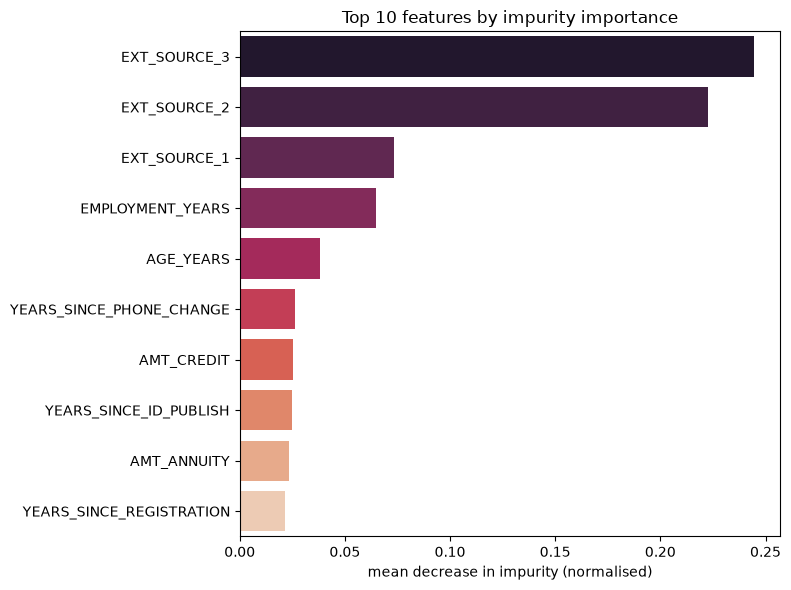

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

best_rf = rf_search.best_estimator_
rf_features = best_rf.named_steps["prep"].get_feature_names_out()
importances = pd.Series(best_rf.named_steps["model"].feature_importances_, index=[n.split("__", 1)[1] for n in rf_features])

print(f"{len(importances)} features in   "
      f"{int((importances == 0).sum())} never chosen for a split   "
      f"top 10 hold {importances.nlargest(10).sum():.1%} of the total")

top = importances.nlargest(10)

fig, ax = plt.subplots(figsize=(8, 6))
sns.barplot(y=top.index, x=top.values, ax=ax, hue=top.index, palette="rocket")
ax.set_xlabel("mean decrease in impurity (normalised)")
ax.set_ylabel("")
ax.set_title("Top 10 features by impurity importance")
fig.tight_layout()
fig.savefig(f"{REPORTS_DIR}/figures/rf_feature_importance.png", dpi=150)
plt.show()

### 2.4) XGBoost

`scale_pos_weight` accounts for class imbalance. `learning_rate=0.05` and `n_estimators=300` are fixed to limit search cost, focusing the search on tree complexity and sampling. `max_depth` and `min_child_weight` control model complexity, with the latter constraining the Hessian mass required to create a leaf rather than its raw sample count. `subsample` and `colsample_bytree` introduce stochasticity to help reduce overfitting. 

In [10]:
from xgboost import XGBClassifier

XGB_SPACE = {
    "model__max_depth": [3, 5, 7],
    "model__min_child_weight": [1, 10, 50],
    "model__subsample": [0.5, 0.7],
    "model__colsample_bytree": [0.3, 0.5],
}

xgb_search = run_search(
    "XGBoost",
    boost_pipe(XGBClassifier(
        n_estimators=300,
        learning_rate=0.05,
        scale_pos_weight=SCALE_POS_WEIGHT,
        enable_categorical=True,
        tree_method="hist",
        n_jobs=1,  # run_search already runs one fit per core; nesting the two oversubscribes
        random_state=RANDOM_STATE,
    )),
    XGB_SPACE,
    n_iter=10
)

save_model(xgb_search, "xgboost.joblib")


XGBoost
  CV AP        0.2386 ± 0.0066
  CV ROC-AUC   0.7542 ± 0.0060
  CV Gini      0.5083
  train AP     0.2933   gap +0.0547
  Search: 10 candidates x 5 folds in 7.4 min
  Best params:  subsample = 0.5, min_child_weight = 10, max_depth = 5, colsample_bytree = 0.5
  (Saved in: ../models/xgboost.joblib   871.1 KB)


### 2.5) LightGBM

`num_leaves` controls tree complexity under LightGBM's leaf-wise growth. `min_child_samples` regularizes leaf size in terms of rows, unlike XGBoost's Hessian-based `min_child_weight`. `subsample_freq=1` activates row sampling; the search tests sampling rates up to 1.0 and feature fractions from 0.3 to 0.8, balancing tree diversity against the information available per tree.

In [11]:
from lightgbm import LGBMClassifier

LGBM_SPACE = {
    "model__num_leaves": [15, 31, 63],
    "model__min_child_samples": [50, 200, 800],
    "model__colsample_bytree": [0.3, 0.5, 0.8],
    "model__subsample": [0.7, 0.85, 1.0],
}

lgbm_search = run_search(
    "LightGBM",
    boost_pipe(LGBMClassifier(
        n_estimators=300,
        learning_rate=0.05,
        scale_pos_weight=SCALE_POS_WEIGHT,
        subsample_freq=1,  # without this, subsample is silently ignored
        n_jobs=1,  # run_search already runs one fit per core; nesting the two oversubscribes
        random_state=RANDOM_STATE,
        verbose=-1,
    )),
    LGBM_SPACE,
    n_iter=10,
)

save_model(lgbm_search, "lightgbm.joblib")


LightGBM
  CV AP        0.2403 ± 0.0074
  CV ROC-AUC   0.7568 ± 0.0064
  CV Gini      0.5136
  train AP     0.2917   gap +0.0514
  Search: 10 candidates x 5 folds in 4.5 min
  Best params:  subsample = 0.85, num_leaves = 31, min_child_samples = 800, colsample_bytree = 0.3
  (Saved in: ../models/lightgbm.joblib   1.1 MB)


### 2.6) Comparison table

In [12]:
MODELS = {
    "Logistic Regression": logreg_search,
    "Decision Tree": tree_search,
    "Random Forest": rf_search,
    "XGBoost": xgb_search,
    "LightGBM": lgbm_search,
}

comparison = pd.DataFrame([
    {
        "Model": name,
        "CV AP": s.cv_results_["mean_test_ap"][s.best_index_],
        "CV AP std": s.cv_results_["std_test_ap"][s.best_index_],
        "CV ROC-AUC": s.cv_results_["mean_test_roc"][s.best_index_],
        "CV ROC-AUC std": s.cv_results_["std_test_roc"][s.best_index_],
        "CV Gini": 2 * s.cv_results_["mean_test_roc"][s.best_index_] - 1
    }
    for name, s in MODELS.items()
])

(comparison.style
    .format({c: "{:.4f}" for c in comparison.columns if c != "Model"})
    .highlight_max(subset=["CV AP", "CV ROC-AUC", "CV Gini"], color="#359d4a")
    .highlight_min(subset=["CV AP std", "CV ROC-AUC std"], color="#359d4a"))

,Model,CV AP,CV AP std,CV ROC-AUC,CV ROC-AUC std,CV Gini
0,Logistic Regression,0.2211,0.0095,0.7460,0.0066,0.4920
1,Decision Tree,0.1930,0.0066,0.7175,0.0071,0.4350
2,Random Forest,0.2234,0.0075,0.7445,0.0066,0.4890
3,XGBoost,0.2386,0.0066,0.7542,0.0060,0.5083
4,LightGBM,0.2403,0.0074,0.7568,0.0064,0.5136


## 3) Final evaluation

### 3.1) Validation scores

In [27]:
from sklearn.metrics import (
    auc,
    average_precision_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve
)

CUTOFF = 0.50  

val_scores = {name: s.best_estimator_.predict_proba(X_val)[:, 1] for name, s in MODELS.items()}

rows = []
for name in comparison["Model"]:
    p = val_scores[name]
    precision, recall, _ = precision_recall_curve(y_val, p)
    rows.append({
        "Model": name,
        "AP": average_precision_score(y_val, p),
        "PR-AUC": auc(recall, precision),
        "ROC-AUC": roc_auc_score(y_val, p),
        "Precision": precision_score(y_val, p >= CUTOFF),
        "Recall": recall_score(y_val, p >= CUTOFF),
    })

validation = pd.DataFrame(rows)

print(f"validation set   {len(y_val):,} rows   {int(y_val.sum()):,} defaulters   "
      f"precision and recall at cutoff {CUTOFF:.2f}")
print()
(validation.style
    .format({c: "{:.4f}" for c in validation.columns if c != "Model"})
    .highlight_max(subset=["AP", "PR-AUC", "ROC-AUC"], color="#359d4a"))

validation set   46,126 rows   3,724 defaulters   precision and recall at cutoff 0.50



,Model,AP,PR-AUC,ROC-AUC,Precision,Recall
0,Logistic Regression,0.2167,0.2164,0.7416,0.1562,0.6665
1,Decision Tree,0.1922,0.2020,0.7145,0.1456,0.6582
2,Random Forest,0.2214,0.2213,0.7397,0.1758,0.5803
3,XGBoost,0.2358,0.2357,0.7518,0.1695,0.6555
4,LightGBM,0.2387,0.2386,0.7532,0.1699,0.6600


### 3.2) ROC & PR curves

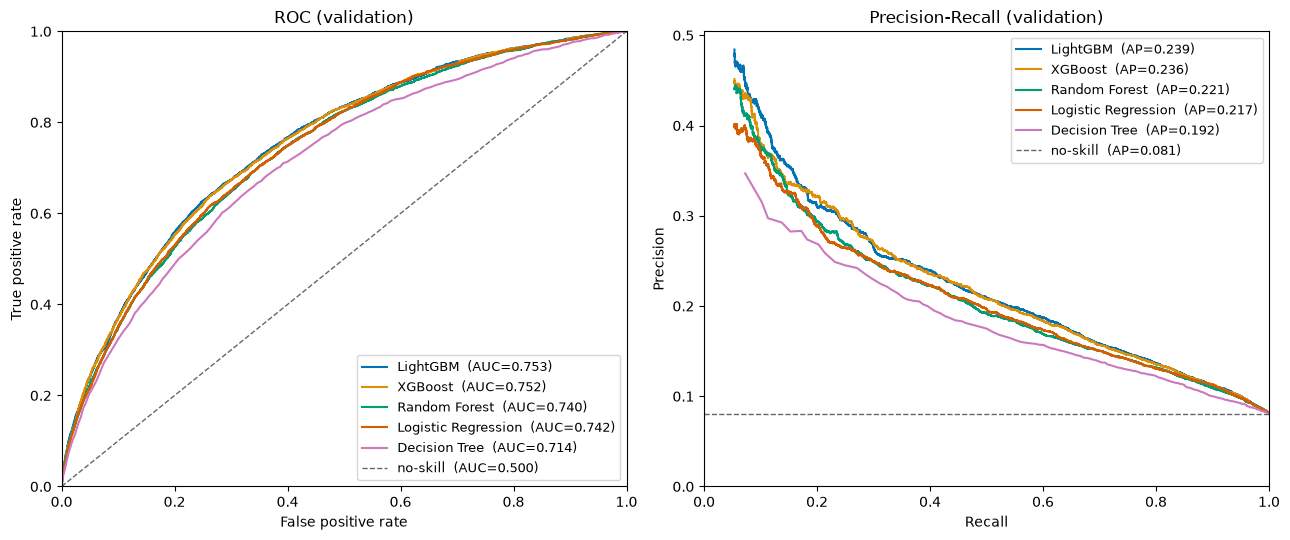

In [28]:
# below roughly 200 defaulters the precision estimate swings on single rows
RECALL_FLOOR = 200 / y_val.sum()

ORDER = comparison.sort_values("CV AP", ascending=False)["Model"].tolist()
BASE_RATE = y_val.mean()

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

for color, name in zip(sns.color_palette("colorblind", len(ORDER)), ORDER):
    scores = val_scores[name]

    fpr, tpr, _ = roc_curve(y_val, scores)
    axes[0].plot(fpr, tpr, color=color, lw=1.5,
                 label=f"{name}  (AUC={roc_auc_score(y_val, scores):.3f})")

    precision, recall, _ = precision_recall_curve(y_val, scores, drop_intermediate=True)
    shown = recall >= RECALL_FLOOR
    axes[1].plot(recall[shown], precision[shown], color=color, lw=1.5,
                 label=f"{name}  (AP={average_precision_score(y_val, scores):.3f})")

axes[0].plot([0, 1], [0, 1], color="0.4", ls="--", lw=1, label="no-skill  (AUC=0.500)")
axes[0].set_title("ROC (validation)")
axes[0].set_xlabel("False positive rate")
axes[0].set_ylabel("True positive rate")
axes[0].set_xlim(0, 1)
axes[0].set_ylim(0, 1)
axes[0].legend(loc="lower right", fontsize=9)

axes[1].axhline(BASE_RATE, color="0.4", ls="--", lw=1, label=f"no-skill  (AP={BASE_RATE:.3f})")
axes[1].set_title(f"Precision-Recall (validation)")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_xlim(0, 1)
axes[1].set_ylim(0, None)
axes[1].legend(loc="upper right", fontsize=9)

fig.tight_layout()
fig.savefig(f"{REPORTS_DIR}/figures/model_comparison_curves.png", dpi=150)
plt.show()

### 3.3) Test set

In [29]:
WINNER = comparison.loc[comparison["CV AP"].idxmax(), "Model"]
test_scores = MODELS[WINNER].best_estimator_.predict_proba(X_test)[:, 1]

precision, recall, _ = precision_recall_curve(y_test, test_scores)

print(f"{WINNER}   test set {len(y_test):,} rows   {int(y_test.sum()):,} defaulters")
print()
print(f"  AP        {average_precision_score(y_test, test_scores):.4f}")
print(f"  PR-AUC    {auc(recall, precision):.4f}")
print(f"  ROC-AUC   {roc_auc_score(y_test, test_scores):.4f}")

LightGBM   test set 46,126 rows   3,724 defaulters

  AP        0.2376
  PR-AUC    0.2374
  ROC-AUC   0.7526


### 3.4) Confusion Matrix

  precision 16.9%   of 14,289 predicted defaults
  recall    64.9%   of 3,724 actual defaults


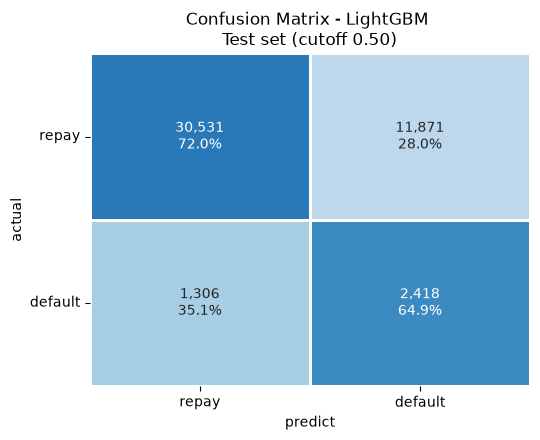

In [42]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, test_scores >= CUTOFF)
tn, fp, fn, tp = cm.ravel()
print(f"  precision {tp / (tp + fp):.1%}   of {tp + fp:,} predicted defaults")
print(f"  recall    {tp / (tp + fn):.1%}   of {tp + fn:,} actual defaults")

cm_share = cm / cm.sum(axis=1, keepdims=True)

labels = np.array([[f"{n:,}\n{s:.1%}" for n, s in zip(row, share)]
                   for row, share in zip(cm, cm_share)])

fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(cm_share, annot=labels, fmt="", cmap="Blues", cbar=False,
            vmin=0, vmax=1, linewidths=1, linecolor="white",
            xticklabels=["repay", "default"],
            yticklabels=["repay", "default"], ax=ax)
ax.tick_params(axis="y", rotation=0)
ax.set_xlabel("predict")
ax.set_ylabel("actual")
ax.set_title(f"Confusion Matrix - {WINNER} \nTest set (cutoff {CUTOFF:.2f})")

fig.tight_layout()
fig.savefig(f"{REPORTS_DIR}/figures/test_confusion_matrix.png", dpi=150)
plt.show()